In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datetime import datetime, date

In [2]:
ds = xr.load_dataset("ERA5_features/grib_files/snow_depth_50_87.grib", engine="cfgrib")
var_daily1 = ds.sd.groupby(ds.sd.time.dt.date).mean()

Ignoring index file 'ERA5_features/grib_files/snow_depth_50_87.grib.5b7b6.idx' incompatible with GRIB file


In [3]:
ds = xr.load_dataset("ERA5_features/grib_files/snow_depth_88_25.grib", engine="cfgrib")
var_daily2 = ds.sd.groupby(ds.sd.time.dt.date).mean()

Ignoring index file 'ERA5_features/grib_files/snow_depth_88_25.grib.5b7b6.idx' incompatible with GRIB file


In [4]:
var_daily = xr.concat([var_daily1, var_daily2], dim='date')
var_daily = var_daily.reset_coords(['number', 'step', 'surface'], drop=True)

In [5]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [6]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [7]:
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})

In [8]:
ds_oro = xr.load_dataset("ERA5_features/grib_files/orography_1deg_res.grib", engine="cfgrib")
ds_oro = ds_oro.reset_coords(['number', 'time', 'step', 'surface', 'valid_time'], drop=True)

Ignoring index file 'ERA5_features/grib_files/orography_1deg_res.grib.5b7b6.idx' incompatible with GRIB file


In [9]:
g = 9.80665
lat = ds_oro.latitude
mount_filt = xr.where(ds_oro.z/g < 1000, 1, 0)

In [10]:
weights = np.cos(np.deg2rad(lat))*mount_filt
weights.name = "weights"

In [11]:
lon_min = -11
lon_max = 19
lat_max = 59
lat_min = 47

var_daily_regmean = var_daily.sel(longitude=slice(lon_min,lon_max), latitude=slice(lat_max,lat_min)).weighted(weights).mean(dim=['longitude', 'latitude'])

In [12]:
var_7dMean_regmean = var_daily_regmean.rolling(time=7, min_periods=7, center=True).mean() 
month = var_7dMean_regmean.time.dt.month
day = var_7dMean_regmean.time.dt.day
var_7dMean_regmean = var_7dMean_regmean.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

var_7dMean_regmean_0 = var_7dMean_regmean.sel(time=slice("1950-07", "1980-06"))
var_7dMean_regmean_1 = var_7dMean_regmean.sel(time=slice("1960-07", "1990-06"))
var_7dMean_regmean_2 = var_7dMean_regmean.sel(time=slice("1970-07", "2000-06"))
var_7dMean_regmean_3 = var_7dMean_regmean.sel(time=slice("1980-07", "2010-06"))
var_7dMean_regmean_4 = var_7dMean_regmean.sel(time=slice("1990-07", "2020-06"))

(0.0, 0.011774396735175404)

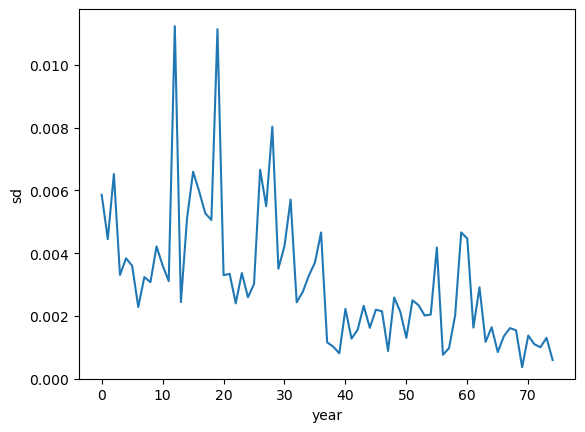

In [13]:
month = var_daily_regmean.time.dt.month
day = var_daily_regmean.time.dt.day
var_daily_regmean = var_daily_regmean.sel(time=~((month == 2) & (day == 29)))
var_daily_regmean.coarsen(time=151).construct(time=("year", "date")).mean(dim='date').plot()
plt.ylim(bottom=0)

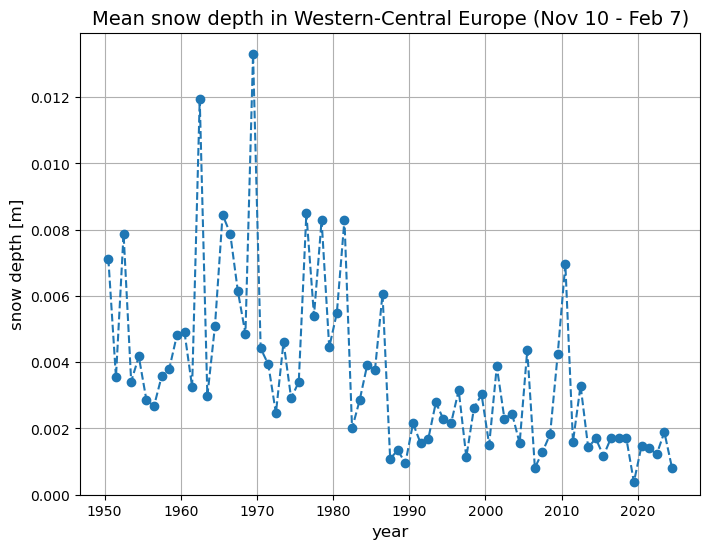

In [38]:
month = var_7dMean_regmean.time.dt.month
day = var_7dMean_regmean.time.dt.day
var_7dMean_regmean_week3 = var_7dMean_regmean.sel(time = ((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4)))
var_wintermean_regmean_week3 = var_7dMean_regmean_week3.coarsen(time=84).construct(time=("year", "date")).mean(dim='date')

plt.figure(figsize=(8,6))
plt.plot(np.arange(1950.5, 2025, 1), var_wintermean_regmean_week3, 'o--')
plt.title('Mean snow depth in Western-Central Europe (Nov 10 - Feb 7)',fontsize=14)
plt.xlabel('year',fontsize=12)
plt.ylabel('snow depth [m]',fontsize=12)
plt.tick_params(labelsize=10)
plt.ylim(bottom=0)
plt.grid()

plt.savefig('WCE_snow.pdf', bbox_inches='tight')

In [24]:
print(var_wintermean_regmean_week3[:60].mean())
print(var_wintermean_regmean_week3[60:].mean())

<xarray.DataArray 'sd' ()> Size: 8B
array(0.00405931)
<xarray.DataArray 'sd' ()> Size: 8B
array(0.00189734)


In [28]:
var_wintermean_regmean_week3[60:]

<xarray.DataArray 'sd' (year: 15)> Size: 120B
array([0.0069619 , 0.00159682, 0.00329463, 0.00142597, 0.00169809,
       0.00117089, 0.00171732, 0.00170743, 0.00171206, 0.00037971,
       0.00146892, 0.00139687, 0.00122501, 0.00188768, 0.0008168 ])
Dimensions without coordinates: year

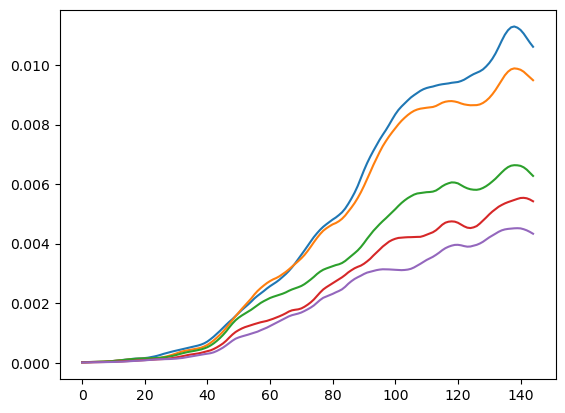

In [14]:
seasonal_cycle = var_7dMean_regmean_0.groupby('month_day').mean()
plt.plot(range(145), np.concatenate([seasonal_cycle[56:], seasonal_cycle[:56]]))
seasonal_cycle = var_7dMean_regmean_1.groupby('month_day').mean()
plt.plot(range(145), np.concatenate([seasonal_cycle[56:], seasonal_cycle[:56]]))
seasonal_cycle = var_7dMean_regmean_2.groupby('month_day').mean()
plt.plot(range(145), np.concatenate([seasonal_cycle[56:], seasonal_cycle[:56]]))

seasonal_cycle = var_7dMean_regmean_3.groupby('month_day').mean()
plt.plot(range(145), np.concatenate([seasonal_cycle[56:], seasonal_cycle[:56]]))
seasonal_cycle = var_7dMean_regmean_4.groupby('month_day').mean()
plt.plot(range(145), np.concatenate([seasonal_cycle[56:], seasonal_cycle[:56]]))

In [15]:
var_7dMean_regmean_deseas_0 = var_7dMean_regmean.sel(time=slice("1950-07", "1990-06")).groupby('month_day') - var_7dMean_regmean_0.groupby('month_day').mean()
var_7dMean_regmean_deseas_1 = var_7dMean_regmean.sel(time=slice("1990-07", "2000-06")).groupby('month_day') - var_7dMean_regmean_1.groupby('month_day').mean()
var_7dMean_regmean_deseas_2 = var_7dMean_regmean.sel(time=slice("2000-07", "2010-06")).groupby('month_day') - var_7dMean_regmean_2.groupby('month_day').mean()
var_7dMean_regmean_deseas_3 = var_7dMean_regmean.sel(time=slice("2010-07", "2020-06")).groupby('month_day') - var_7dMean_regmean_3.groupby('month_day').mean()
var_7dMean_regmean_deseas_4 = var_7dMean_regmean.sel(time=slice("2020-07", "2025-06")).groupby('month_day') - var_7dMean_regmean_4.groupby('month_day').mean()

In [16]:
var_7dMean_regmean_deseas_detr = xr.concat([var_7dMean_regmean_deseas_0, var_7dMean_regmean_deseas_1, var_7dMean_regmean_deseas_2, 
                                            var_7dMean_regmean_deseas_3, var_7dMean_regmean_deseas_4], dim='time')

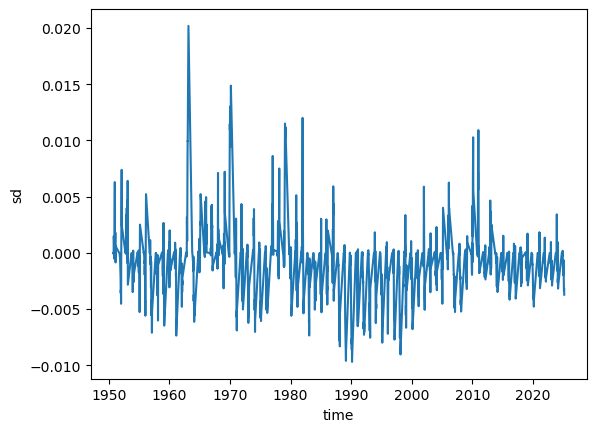

In [17]:
var_7dMean_regmean_deseas_detr.plot()

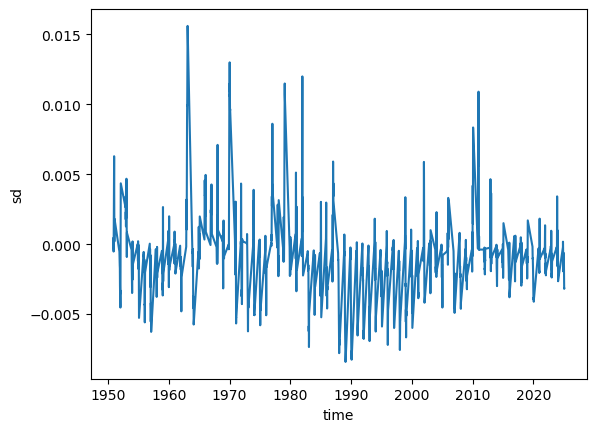

In [18]:
month = var_7dMean_regmean_deseas_detr.time.dt.month
day = var_7dMean_regmean_deseas_detr.time.dt.day
var_7dMean_regmean_deseas_detr_week3 = var_7dMean_regmean_deseas_detr.sel(time = ((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4)))
var_7dMean_regmean_deseas_detr_week4 = var_7dMean_regmean_deseas_detr.sel(time = ((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28)))
var_7dMean_regmean_deseas_detr_week5 = var_7dMean_regmean_deseas_detr.sel(time = ((month == 10) & (day >= 30)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 21)))
var_7dMean_regmean_deseas_detr_week6 = var_7dMean_regmean_deseas_detr.sel(time = ((month == 10) & (day >= 23)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 14)))
var_7dMean_regmean_deseas_detr_week7 = var_7dMean_regmean_deseas_detr.sel(time = ((month == 10) & (day >= 16)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 7)))
var_7dMean_regmean_deseas_detr_week3.plot()

In [19]:
df_var_week3 = var_7dMean_regmean_deseas_detr_week3.to_dataframe(name='snow_depth')
df_var_week3 = df_var_week3.drop(['month_day'], axis=1)
df_var_week3

,snow_depth
time,
1950-11-13,-0.002929
1950-11-14,-0.002619
1950-11-15,-0.002343
1950-11-16,-0.002217
1950-11-17,-0.002153
...,...
2025-01-31,-0.010937
2025-02-01,-0.010961
2025-02-02,-0.011063


In [20]:
df_var_week4 = var_7dMean_regmean_deseas_detr_week4.to_dataframe(name='snow_depth')
df_var_week4 = df_var_week4.drop(['month_day'], axis=1)
df_var_week4

,snow_depth
time,
1950-11-06,-0.005969
1950-11-07,-0.005807
1950-11-08,-0.005509
1950-11-09,-0.004978
1950-11-10,-0.004392
...,...
2025-01-24,-0.010872
2025-01-25,-0.010810
2025-01-26,-0.010791


In [21]:
df_var_week5 = var_7dMean_regmean_deseas_detr_week5.to_dataframe(name='snow_depth')
df_var_week5 = df_var_week5.drop(['month_day'], axis=1)
df_var_week5

,snow_depth
time,
1950-10-30,-0.005113
1950-10-31,-0.005221
1950-11-01,-0.005389
1950-11-02,-0.005624
1950-11-03,-0.005838
...,...
2025-01-17,-0.007402
2025-01-18,-0.008688
2025-01-19,-0.009763


In [19]:
df_var_week6 = var_7dMean_regmean_deseas_detr_week6.to_dataframe(name='snow_depth')
df_var_week6 = df_var_week6.drop(['month_day'], axis=1)
df_var_week6

,snow_depth
time,
1950-10-23,-0.003702
1950-10-24,-0.003909
1950-10-25,-0.004142
1950-10-26,-0.004353
1950-10-27,-0.004575
...,...
2025-01-10,-0.000831
2025-01-11,-0.000978
2025-01-12,-0.001420


In [20]:
df_var_week7 = var_7dMean_regmean_deseas_detr_week7.to_dataframe(name='snow_depth')
df_var_week7 = df_var_week7.drop(['month_day'], axis=1)
df_var_week7

,snow_depth
time,
1950-10-16,-0.002901
1950-10-17,-0.003042
1950-10-18,-0.003144
1950-10-19,-0.003248
1950-10-20,-0.003330
...,...
2025-01-03,-0.003047
2025-01-04,-0.002641
2025-01-05,-0.002178


In [20]:
df_var_week3.to_csv('snow_NE_week3.csv')

In [22]:
df_var_week4.to_csv('snow_NE_week4.csv')
df_var_week5.to_csv('snow_NE_week5.csv')

In [21]:
df_var_week6.to_csv('snow_NE_week6.csv')
df_var_week7.to_csv('snow_NE_week7.csv')